# SDS Mini Datathon 2026: Submission Notebook

**Team name:** Mixue lovers

**Members:** Xiong Zirui, Lee Juin Hsien Justin, Chew Zhan Shi Jordan

---

### Before you start
- Keep every section heading below, in this order. You may add cells and sub-headings inside each section.
- This notebook must run on **Python 3.14** using **Restart & Run All**, with no errors, in under **10 minutes**.
- Every chart in your deck must be generated in this notebook.
- Load data from the `data/` folder using relative paths only. Do not load data live from a website or API.
- Delete these instruction cells (the ones starting with *Instructions*) before submitting if you like, but keep the headings.

### Before you submit
1. Kernel → **Restart & Run All**, and check there are no errors.
2. Save the notebook with all outputs.
3. Export it as `main.html` (File → Save and Export Notebook As → HTML).
4. Zip the `TeamName/` folder: `main.ipynb`, `main.html`, `requirements.txt`, `deck.pdf`, `data/`.

## 1. Setup & Imports

*Instructions:* Import every library you use here. Each one must be listed, with its exact version, in `requirements.txt`.

In [ ]:
import sys
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

# Add other libraries here, e.g.
# import seaborn as sns
# from sklearn.linear_model import LinearRegression

In [ ]:
# Python version check: the judges' environment uses Python 3.14
print(f"Python version: {sys.version.split()[0]}")
if sys.version_info[:2] != (3, 14):
    print("WARNING: this notebook will be run on Python 3.14. Please test it on 3.14 before submitting.")

In [ ]:
# Random seed: keep this so your results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# If you use other libraries with randomness, set their seeds too,
# e.g. random_state=SEED in scikit-learn models

In [ ]:
# Display settings (optional)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Data Ingestion

*Instructions:* Load all data from the `data/` folder using relative paths. If you use any additional public datasets, download them into `data/` and cite them in Section 9.

In [ ]:
# Provided datasets (update the file names if needed)
coe = pd.read_csv("data/COEBiddingResultsPrices.csv")
registrations = pd.read_csv("data/NewRegistrationofCarsbyMake.csv")

print(f"COE bidding data: {coe.shape[0]:,} rows, {coe.shape[1]} columns")
print(f"Registration data: {registrations.shape[0]:,} rows, {registrations.shape[1]} columns")

In [26]:
coe.head()

,year,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium,date
0,2010,1,1,Category A,1152,1145,1342,18.502,2010-01-01
1,2010,1,1,Category B,687,679,883,19.190,2010-01-01
2,2010,1,1,Category C,173,173,265,19.001,2010-01-01
3,2010,1,1,Category D,373,365,509,0.889,2010-01-01
4,2010,1,1,Category E,586,567,1011,19.889,2010-01-01


In [23]:
registrations.head()

,year,month,make,importer_type,fuel_type,vehicle_type,number,number_original,number_imputed
0,2016,1,ALFA ROMEO,NaN,Petrol,Hatchback,3,3.0,False
1,2016,1,ALPINA,NaN,Petrol,Hatchback,0,0.0,False
2,2016,1,ASTON MARTIN,NaN,Petrol,Hatchback,0,0.0,False
3,2016,1,AUDI,NaN,Petrol,Hatchback,45,45.0,False
4,2016,1,B.M.W.,NaN,Petrol,Hatchback,5,5.0,False


## 3. Data Cleaning

*Instructions:* Show every cleaning step, with a short note on why. For example: fixing data types, handling missing values, removing duplicates, and aggregating registrations to monthly totals before joining with the COE data.

**Reminder:** the two datasets overlap from January 2016 to May 2025.

### COE Dataframe

In [ ]:
# split month into year and month
coe[['year', 'month']] = coe['month'].str.split('-', expand=True)
coe['year'] = coe['year'].astype(int)
coe['month'] = coe['month'].astype(int)
col = coe.pop("year")
coe.insert(0, "year", col)

# Create monthly date variable
coe["date"] = pd.to_datetime(
    coe[["year", "month"]].assign(day=1)
)

# change to int
cols = ["bids_received", "bids_success"]
coe[cols] = coe[cols].apply(
    lambda col: col.astype(str).str.replace(",", "", regex=False).astype(int))

coe['bids_success'] = coe['bids_success'].astype(int)
coe['bids_received'] = coe['bids_received'].astype(int)

In [ ]:
# Normalise premium column
coe["premium"] = coe["premium"] / 1000
coe["premium"].describe()

In [24]:
# generate summary for each column
summary = pd.DataFrame({
    "dtype": coe.dtypes,
    "non_null": coe.count(),
    "missing": coe.isna().sum(),
    "missing_pct": coe.isna().mean() * 100,
    "unique": coe.nunique()
})

display(summary)

,dtype,non_null,missing,missing_pct,unique
year,int64,1990,0,0.0,17
month,int64,1990,0,0.0,12
bidding_no,int64,1990,0,0.0,2
vehicle_class,str,1990,0,0.0,5
quota,int64,1990,0,0.0,867
bids_success,int64,1990,0,0.0,894
bids_received,int64,1990,0,0.0,1124
premium,float64,1990,0,0.0,1609


### Registrations Dataframe

In [ ]:
# split month into year and month
registrations[['year', 'month']] = registrations['month'].str.split('-', expand=True)
registrations['year'] = registrations['year'].astype(int)
registrations['month'] = registrations['month'].astype(int)
col = registrations.pop("year")
registrations.insert(0, "year", col)

#### importer_type column

In [ ]:
# Missing importer type by year
registrations.groupby("year")["importer_type"].apply(
    lambda x: x.isna().mean() * 100
)

Missing values for importer_type is highly structured as seen above. However, it is difficult to determine the significance of these NaN values without additional data. As this variable is not significant to our analysis, no modifications will be done.

#### numbers column

In [ ]:
# Missing number values by year
registrations.groupby("year")["number"].agg(
    total_rows="size",
    missing=lambda x: x.isna().sum(),
    missing_pct=lambda x: x.isna().mean() * 100
)

Missing values appeard from 2018 onwards. Further checks are conducted to determine if there is a change in data representation format.

In [ ]:
# Determining number of missings values, 0s and non-zeros
zero_by_year = (
    registrations.groupby("year")["number"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum(),
        zeros=lambda x: (x == 0).sum(),
        positive=lambda x: (x > 0).sum()
    )
)

zero_by_year["zero_pct"] = (zero_by_year["zeros"] / zero_by_year["total"] * 100)
zero_by_year["missing_pct"] = (zero_by_year["missing"] / zero_by_year["total"] * 100)

display(zero_by_year)

2018 marked the transition from using "0" to "missing values" to represent the idea of "no entries for this category". The exact month of transition (July 2018) is shown in the table below.

In [ ]:
# Determine exact month of transition from 0 to non-zero values in 2018
transition = (
    registrations[registrations["year"] == 2018]
    .groupby("month")["number"]
    .agg(
        total="size",
        zeros=lambda x: (x == 0).sum(),
        missing=lambda x: x.isna().sum(),
        positive=lambda x: (x > 0).sum()
    )
)

transition["zero_pct"] = (
    transition["zeros"] / transition["total"] * 100)

transition["missing_pct"] = (
    transition["missing"] / transition["total"] * 100)

display(transition)

In [ ]:
# Preserve original values
registrations["number_original"] = registrations["number"]

# Track imputed observations
registrations["number_imputed"] = registrations["number"].isna()

# Replace missing values with zero
registrations["number"] = registrations["number"].fillna(0).astype(int)

For quantitative analysis, we replaced missing values after July 2018 with 0. This change is tracked by the number_imputed column. Original data is also preserved for future validation of this method of cleaning. 

In [ ]:
summary = pd.DataFrame({
    "dtype": registrations.dtypes,
    "non_null": registrations.count(),
    "missing": registrations.isna().sum(),
    "missing_pct": registrations.isna().mean() * 100,
    "unique": registrations.nunique()
})

display(summary)

In [ ]:
registrations.head()

## 4. Exploratory Data Analysis

*Instructions:* Explore the data to understand trends and patterns before modelling. Look out for structural breaks, such as the 2020 bidding suspension and the change in Category A/B definitions.

In [27]:
ab_df = coe.query("vehicle_class in ['Category A', 'Category B']").copy()

ab_df["d_pressure"] = (ab_df["bids_received"] / ab_df["quota"].replace(0, np.nan))

# calculate monthly mean of premium and demand pressure for each vehicle class
monthly = (
    ab_df
    .groupby(["date", "vehicle_class"], as_index=False)
    .agg(
        avg_premium=("premium", "mean"),
        avg_d_pressure=("d_pressure", "mean")
    )
)

# Monthly premiums
premium = monthly.pivot(
    index="date",
    columns="vehicle_class",
    values="avg_premium"
)

# Monthly demand pressure
pressure = monthly.pivot(
    index="date",
    columns="vehicle_class",
    values="avg_d_pressure"
)

# Difference between Category B and A premiums
premium["difference"] = (
    premium["Category B"] - premium["Category A"]
)

In [32]:
# Check the number of observations in Apr-Jun 2020
coe[
    coe["date"].between("2020-04-01", "2020-06-30")
].groupby("date").size()

Series([], dtype: int64)

In [33]:
# Create a complete monthly date index
full_dates = pd.date_range(
    start=monthly["date"].min(),
    end=monthly["date"].max(),
    freq="MS"
)

# Reindex to include missing months
premium = premium.reindex(full_dates)
pressure = pressure.reindex(full_dates)

# Explicitly set Apr-Jun 2020 to NaN
missing_period = (premium.index >= "2020-04-01") & (
    premium.index <= "2020-06-01"
)

premium.loc[missing_period, :] = np.nan
pressure.loc[missing_period, :] = np.nan

# Recalculate premium difference
premium["difference"] = (
    premium["Category B"] - premium["Category A"]
)

## 5. Analysis & Modelling

*Instructions:* Explain your method and why you chose it. If you build a model:
- Use **time-based validation** (train on earlier data, test on later data). Do not use random splits.
- Compare against **simple baselines**, such as the previous round's premium or a rolling average.
- **Bids received** is only known after a round closes. Use it to explain premiums, not to forecast them.
- A merged Category A/B premium cannot be observed. If you model one, state your assumption and test how sensitive your results are to it.

A model is not required. A well-reasoned statistical or descriptive analysis is fine.

In [ ]:
# Your analysis here

## 6. Visualisations

*Instructions:* Generate every chart used in your deck here. Each chart should have a clear title, labelled axes with units, and a one-line takeaway in a markdown cell below it.

In [37]:
# Defined functions to annotate the graphs with significant events and gaps
# Significant COE event dates
event_dates = pd.to_datetime([
    "2014-02-01",
    "2018-02-01",
    "2022-05-01",
    "2022-07-01"
])

# COVID-19 bidding suspension
gap_start = pd.Timestamp("2020-04-01")
gap_end = pd.Timestamp("2020-07-01")

def add_annotations(ax):
    # Red dashed lines for significant events
    for date in event_dates:
        ax.axvline(
            x=date,
            color="red",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

    # Grey shaded region
    ax.axvspan(
        gap_start, gap_end,
        color="grey",
        alpha=0.2,
        zorder=0
    )

    # Black dotted borders
    for date in [gap_start, gap_end]:
        ax.axvline(
            x=date,
            color="black",
            linestyle=":",
            linewidth=1.5
        )

    ax.grid(alpha=0.3)

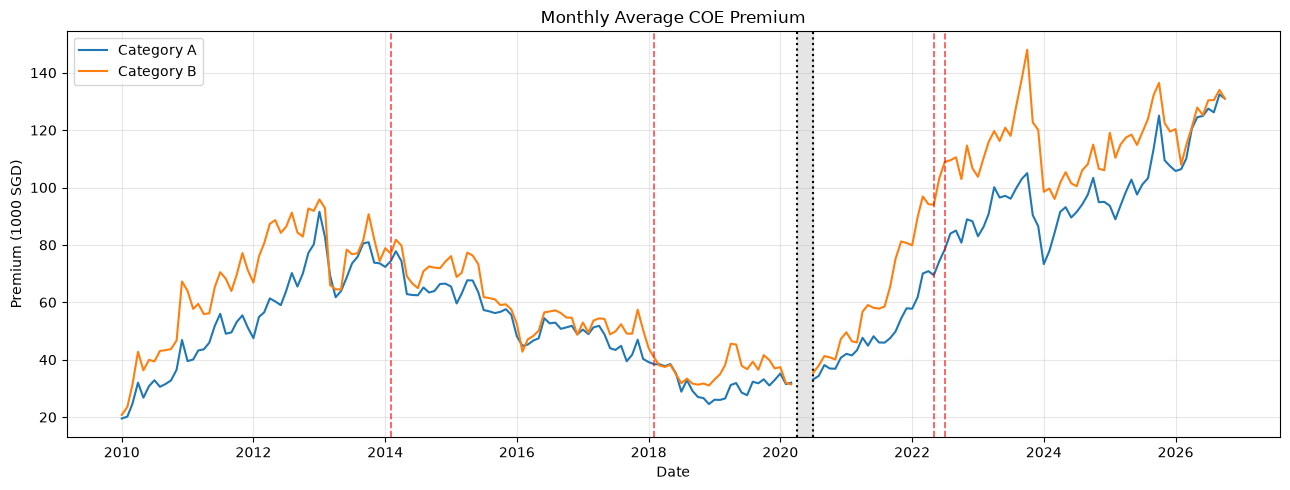

In [41]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    premium.index,
    premium["Category A"],
    label="Category A"
)

ax.plot(
    premium.index,
    premium["Category B"],
    label="Category B"
)

add_annotations(ax)

ax.set_title("Monthly Average COE Premium")
ax.set_ylabel("Premium (1000 SGD)")
ax.set_xlabel("Date")
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

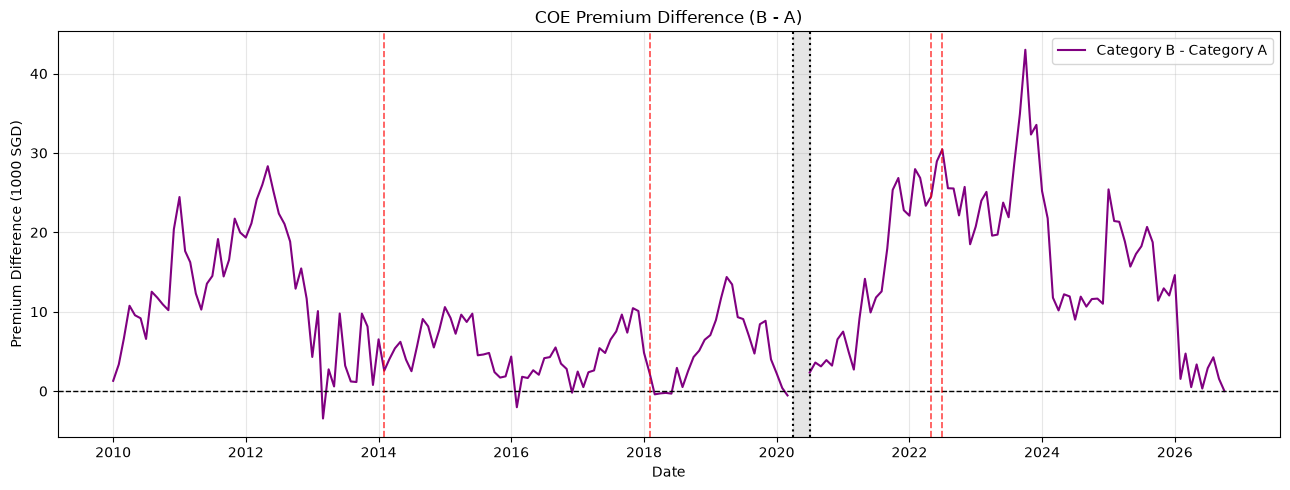

In [42]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    premium.index,
    premium["difference"],
    color="purple",
    label="Category B - Category A"
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

add_annotations(ax)

ax.set_title("COE Premium Difference (B - A)")
ax.set_ylabel("Premium Difference (1000 SGD)")
ax.set_xlabel("Date")
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

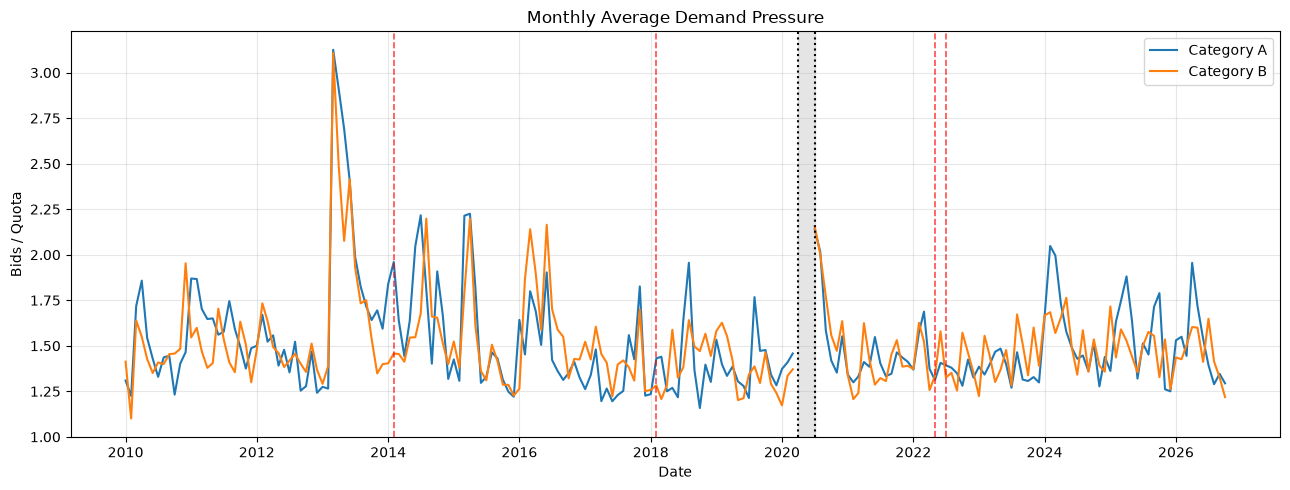

In [40]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    pressure.index,
    pressure["Category A"],
    label="Category A"
)

ax.plot(
    pressure.index,
    pressure["Category B"],
    label="Category B"
)

add_annotations(ax)

ax.set_title("Monthly Average Demand Pressure")
ax.set_ylabel("Bids / Quota")
ax.set_xlabel("Date")
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

## 7. Key Findings & Recommendation

*Instructions:* Summarise your main findings and state your recommendation. This should match your deck.

**Recommendation:** [Your recommendation in one or two sentences]

**Key findings:**
1. [Finding 1]
2. [Finding 2]
3. [Finding 3]

## 8. Assumptions & Limitations

**What the data shows:**
- [Supported directly by the data]

**What we assumed:**
- [Assumption, and how sensitive your conclusions are to it]

**What is speculation:**
- [Interpretation not directly supported by the data]

**Limitations:**
- [Limitation 1]
- [Limitation 2]

## 9. Data Sources & Declarations

**Data sources:**
| Dataset | Source (link) | Date downloaded |
| --- | --- | --- |
| COE bidding results | [Provided by SDS] | – |
| Vehicle registrations | [Provided by SDS] | – |
| [Additional dataset, if any] | [Link] | [DD MMM YYYY] |

**AI tool use:** [State whether and how you used AI tools, e.g. "Used ChatGPT for debugging plotting code."]